# BreastMNIST: which selector gives the best subset of embedding dimensions?

A small classifier on top of a frozen ResNet-50, for 780 ultrasound images.
Feature selection picks `k` of the 2,048 embedding dimensions before the
classifier. Three parts:

1. **Drop-in comparison.** A scikit-learn `Pipeline` where only the selector
   step changes. ROC AUC over 20 random splits, against the random control.
2. **Leakage simulation.** With shuffled labels there is nothing to learn.
   Selecting inside each split gives chance; selecting before splitting does
   not.
3. **The full experiment.** The config-driven run of
   `configs/experiment_breastmnist.yaml`, summarized.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parents[2]))  # repo root, so featsel_datasets imports

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from featsel.selectors import (
    ANOVAFSelector,
    LassoSelector,
    RandomSelector,
    TreeImportanceSelector,
)
from featsel_datasets.medmnist_breastmnist.featsel_view import load_xy

X, y = load_xy()
print(X.shape, y.value_counts().to_dict())

SPLITS = StratifiedShuffleSplit(n_splits=20, train_size=0.7, random_state=42)
K = [5, 10, 25, 50, 100, 250, 500]

# Categorical palette, fixed order (validated: colour-blind safe; two light
# hues need labels, so every series also has its own marker and a direct label).
STYLE = {
    'Random':          ('#2a78d6', 'o'),
    'ANOVA F':         ('#eb6834', 's'),
    'Lasso':           ('#1baf7a', '^'),
    'Tree importance': ('#eda100', 'D'),
}

(780, 2048) {'benign_or_normal': 570, 'malignant': 210}


## 1. Drop-in comparison

ROC AUC treats *malignant* as the positive class. Each selector is the only
step that changes in the pipeline. The random control draws a new subset for
each of five seeds, and their scores are pooled.

In [2]:
SELECTORS = {
    'Random':          lambda k, seed: RandomSelector(n_features=k, random_state=seed),
    'ANOVA F':         lambda k, seed: ANOVAFSelector(n_features=k),
    'Lasso':           lambda k, seed: LassoSelector(n_features=k, C=1.0, random_state=seed),
    'Tree importance': lambda k, seed: TreeImportanceSelector(n_features=k, n_estimators=200,
                                                              random_state=seed),
}

def auc(selector, X=X, y=y):
    steps = [StandardScaler()] + ([selector] if selector is not None else [])
    pipe = make_pipeline(*steps, LogisticRegression(max_iter=1000))
    return cross_val_score(pipe, X, y, cv=SPLITS, scoring='roc_auc', n_jobs=-1)

rows = []
for name, make in SELECTORS.items():
    seeds = range(5) if name == 'Random' else [0]
    for k in K:
        scores = np.concatenate([auc(make(k, seed)) for seed in seeds])
        rows.append({'selector': name, 'k': k, 'auc_median': np.median(scores),
                     'auc_q1': np.quantile(scores, 0.25), 'auc_q3': np.quantile(scores, 0.75)})
results = pd.DataFrame(rows)
all_features = np.median(auc(None))
print(f'All 2,048 dimensions, no selection: median AUC {all_features:.3f}')
results.pivot(index='k', columns='selector', values='auc_median').round(3)

All 2,048 dimensions, no selection: median AUC 0.921


selector,ANOVA F,Lasso,Random,Tree importance
k,,,,
5,0.784,0.728,0.619,0.805
10,0.809,0.770,0.648,0.812
25,0.837,0.829,0.711,0.856
50,0.856,0.847,0.784,0.865
100,0.860,0.884,0.803,0.869
250,0.879,0.907,0.843,0.868
500,0.891,0.905,0.870,0.896


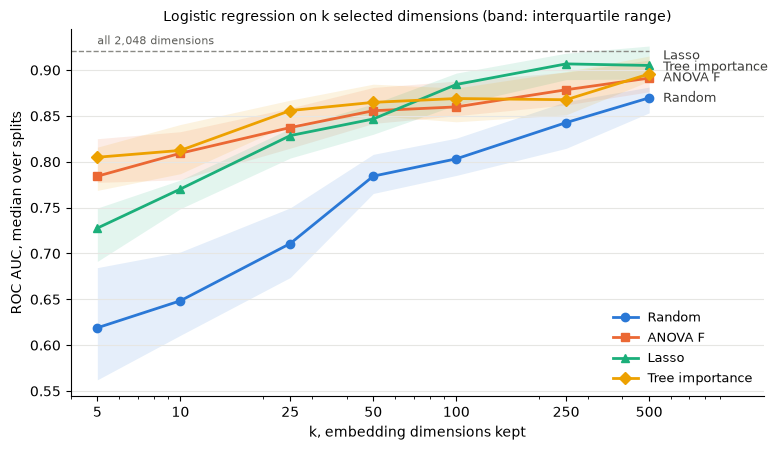

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for name, (color, marker) in STYLE.items():
    part = results[results.selector == name]
    ax.fill_between(part.k, part.auc_q1, part.auc_q3, color=color, alpha=0.12, linewidth=0)
    ax.plot(part.k, part.auc_median, color=color, marker=marker, markersize=6,
            linewidth=2, label=name)

# Direct labels at the right end, pushed apart so they do not overlap.
ends = results[results.k == K[-1]].sort_values('auc_median')
label_y, gap = [], 0.012
for value in ends.auc_median:
    label_y.append(max(value, label_y[-1] + gap) if label_y else value)
for name, y_label in zip(ends.selector, label_y):
    ax.annotate(name, (K[-1], y_label), xytext=(10, 0), textcoords='offset points',
                va='center', fontsize=9, color='#3b3b39')
ax.hlines(all_features, K[0] * 0.8, K[-1], color='#8a8a85', linewidth=1, linestyle='--')
ax.annotate('all 2,048 dimensions', (K[0], all_features), xytext=(0, 5),
            textcoords='offset points', fontsize=8, color='#5f5f5b')
ax.set_xscale('log')
ax.set_xticks(K, [str(k) for k in K])
ax.set_xlim(K[0] * 0.8, K[-1] * 2.6)
ax.set_xlabel('k, embedding dimensions kept')
ax.set_ylabel('ROC AUC, median over splits')
ax.set_title('Logistic regression on k selected dimensions (band: interquartile range)',
             fontsize=10)
ax.grid(axis='y', color='#e6e6e3', linewidth=0.8)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc='lower right')
fig.tight_layout()

Every selector beats the random control at small `k`. No subset up to
`k = 500` beats all 2,048 dimensions with this classifier: selection buys a
smaller model here, not a better one.

For reference, MedMNIST v2 reports test AUC 0.891 to 0.901 for a ResNet-18
trained end to end on BreastMNIST, on its fixed test split. The numbers here
come from a frozen network, a linear classifier and random splits, so they
are not directly comparable.

## 2. Leakage simulation

Shuffle the labels, so that no feature carries information. Then:

- **Selection inside the split** (the pipeline above): ANOVA F picks 50
  dimensions on each training part only.
- **Selection before the split:** ANOVA F picks 50 dimensions on all 780
  images first, then the classifier is cross-validated on them.

The second is the error described by Ambroise and McLachlan (PNAS 2002).

In [4]:
rng = np.random.default_rng(0)
shuffled = pd.Series(rng.permutation(y.to_numpy()), index=y.index)

inside = auc(ANOVAFSelector(n_features=50), y=shuffled)
chosen = ANOVAFSelector(n_features=50).fit(X, shuffled).get_support()
before = auc(None, X=X.loc[:, chosen], y=shuffled)

pd.DataFrame({'median AUC': [np.median(inside), np.median(before)],
              'lowest': [inside.min(), before.min()],
              'highest': [inside.max(), before.max()]},
             index=['selection inside each split', 'selection before splitting']).round(3)

,median AUC,lowest,highest
selection inside each split,0.465,0.367,0.553
selection before splitting,0.645,0.592,0.689


Inside each split, AUC stays around 0.5: there is nothing to find, and
nothing is found. Selecting before splitting lets the shuffled labels choose
the features, and the score rises above chance with no real signal. This is
why the runner fits every selector on the training part only.

## 3. The full experiment

`python -m featsel.run --config configs/experiment_breastmnist.yaml` runs the
whole grid: 4 selectors x 7 values of k x 5 classifiers x 3 training
fractions x 100 splits. Below: median macro-F1 for logistic regression at
training fraction 0.7.

In [5]:
from featsel.analysis import summarize

path = Path.cwd().parents[2] / 'results' / 'experiment_breastmnist.csv'
summary = summarize(pd.read_csv(path))
cell = summary[(summary.model == 'logistic_regression') & (summary.train_size == 0.7)]
cell.pivot(index='k', columns='selector', values='macro_f1_median').round(3)

selector,ANOVAFSelector,LassoSelector,RandomSelector,TreeImportanceSelector
k,,,,
5,0.716,0.649,0.437,0.703
10,0.734,0.703,0.509,0.736
25,0.762,0.747,0.618,0.770
50,0.778,0.785,0.679,0.788
100,0.779,0.806,0.728,0.779
250,0.790,0.831,0.757,0.798
500,0.819,0.837,0.803,0.822


In [6]:
cost = summary[summary.model == 'logistic_regression'].groupby('selector')[
    ['selection_time_s_median', 'fit_time_s_median']].median()
cost.round(3)

,selection_time_s_median,fit_time_s_median
selector,,
ANOVAFSelector,0.014,0.012
LassoSelector,0.178,0.008
RandomSelector,0.002,0.009
TreeImportanceSelector,6.774,0.012
